# Name : Luqman Khan
# SID :  S2024266054

# Task 2 — Dense Network vs. CNN on CIFAR-10

**(a) Data Preparation**

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Load CIFAR-10 dataset**

In [3]:

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", x_test.shape)
print("Testing Labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 913s 5us/step
Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000, 1)


**Normalize images**

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


**One-hot encode labels**

In [5]:
y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (50000, 10)
Testing labels shape: (10000, 10)


**Define CIFAR-10 class names**

In [6]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

print("Total Classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, name)

Total Classes: 10
0 Airplane
1 Automobile
2 Bird
3 Cat
4 Deer
5 Dog
6 Frog
7 Horse
8 Ship
9 Truck


**Visualize 8 images per class**

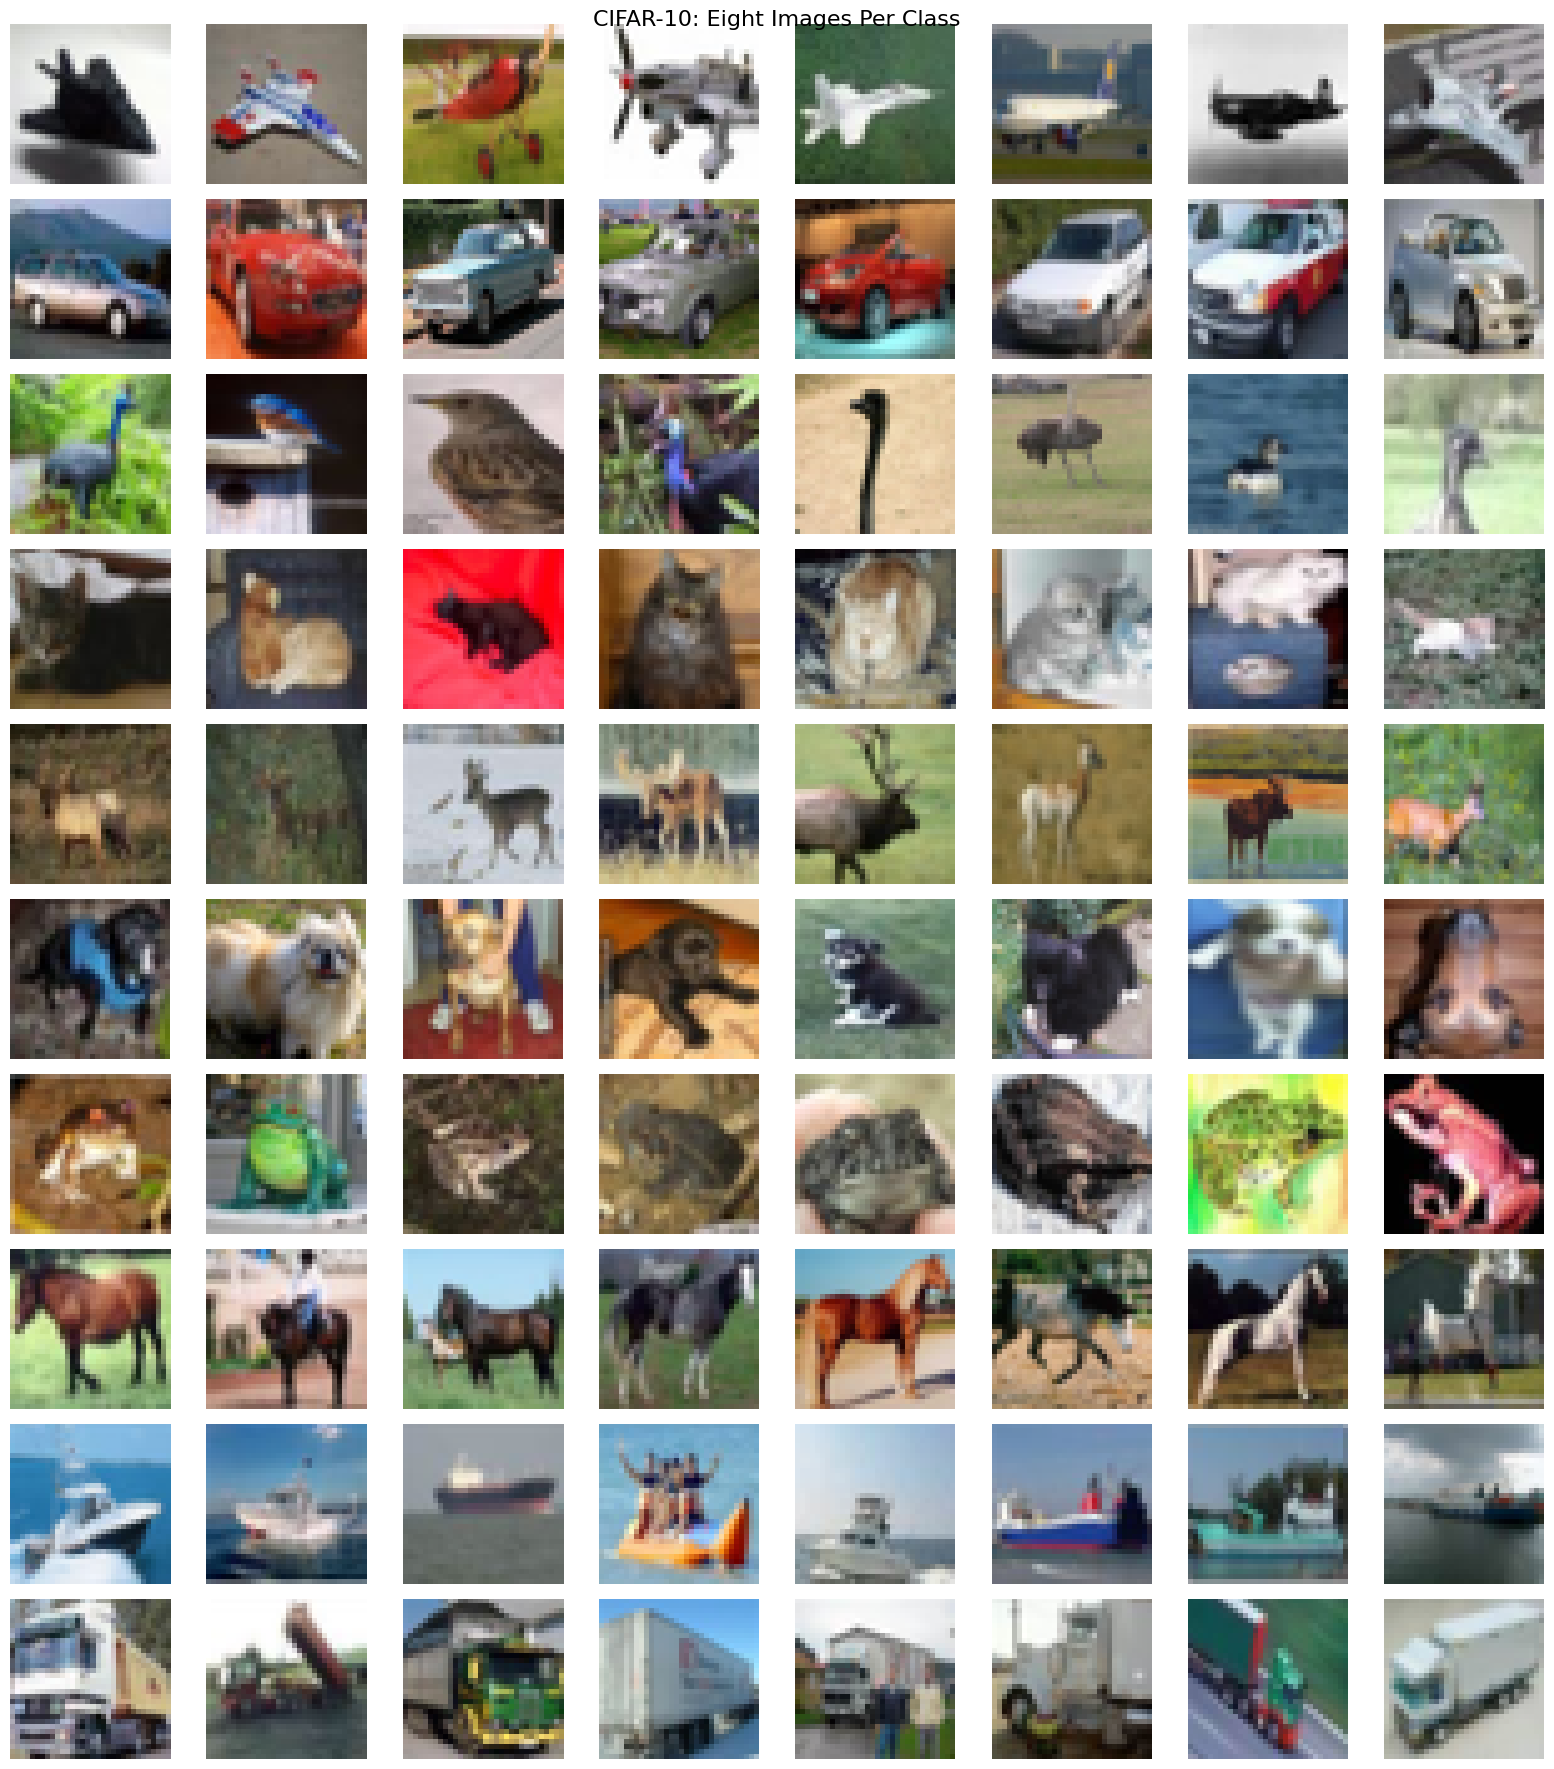

In [7]:

fig, axes = plt.subplots(10, 8, figsize=(16, 18))

for class_id in range(10):
    indices = np.where(np.argmax(y_train, axis=1) == class_id)[0][:8]

    for j, idx in enumerate(indices):

        axes[class_id, j].imshow(x_train[idx])

        axes[class_id, j].axis('off')

        if j == 0:
            axes[class_id, j].set_ylabel(
                class_names[class_id],
                fontsize=10
            )

plt.suptitle("CIFAR-10: Eight Images Per Class", fontsize=16)

plt.tight_layout()
plt.show()

**2(b) Dense Baseline Network : **

Input (32 × 32 × 3)
        |
      Flatten
        |
  Dense (256, ReLU)
        |
  Dense (256, ReLU)
        |
  Dense (10, Softmax)


**Build Dense Network**

In [16]:
dense_model = keras.Sequential([

    layers.Input(shape=(32, 32, 3)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),

    layers.Dense(256, activation='relu'),

    layers.Dense(10, activation='softmax')

], name="Dense_Baseline")



dense_model.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']

)


dense_model.summary()

Model: "Dense_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,050 (3.26 MB)

 Trainable params: 855,050 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

**Verify parameters**

In [17]:
dense_parameters = dense_model.count_params()

print("Dense Network Parameters:", dense_parameters)

print("Hand Calculated Parameters:", 855050)

Dense Network Parameters: 855050
Hand Calculated Parameters: 855050


**Train Dense Network**

In [18]:

class EpochTimer(keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.start_time
        self.epoch_times.append(elapsed)


dense_timer = EpochTimer()


dense_history = dense_model.fit(

    x_train,
    y_train,

    epochs=10,

    batch_size=32,

    validation_split=0.2,

    callbacks=[dense_timer],

    verbose=1

)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.3215 - loss: 1.8709 - val_accuracy: 0.3710 - val_loss: 1.7370
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3927 - loss: 1.6913 - val_accuracy: 0.3976 - val_loss: 1.6712
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4205 - loss: 1.6129 - val_accuracy: 0.4261 - val_loss: 1.6052
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4378 - loss: 1.5659 - val_accuracy: 0.4309 - val_loss: 1.5996
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4518 - loss: 1.5256 - val_accuracy: 0.4334 - val_loss: 1.6043
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4610 - loss: 1.4986 - val_accuracy: 0.4529 - val_loss: 1.5497
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4697 - loss: 1.4770 - val_accuracy: 0.4453 - val_loss: 1.5654
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4743 - loss: 1.4606 - 

**Evaluate Dense Network**

In [19]:

dense_train_loss, dense_train_acc = dense_model.evaluate(
    x_train, y_train, verbose=0
)



dense_test_loss, dense_test_acc = dense_model.evaluate(
    x_test, y_test, verbose=0
)

dense_val_acc = dense_history.history['val_accuracy'][-1]

print("Dense Network Results")

print("Training Accuracy:", dense_train_acc)

print("Validation Accuracy:", dense_val_acc)

print("Testing Accuracy:", dense_test_acc)

print(
    "Average Time Per Epoch:",
    np.mean(dense_timer.epoch_times),
    "seconds"
)

Dense Network Results
Training Accuracy: 0.49187999963760376
Validation Accuracy: 0.4586000144481659
Testing Accuracy: 0.47200000286102295
Average Time Per Epoch: 4.6400601148605345 seconds


**Plot Dense Network accuracy and loss**

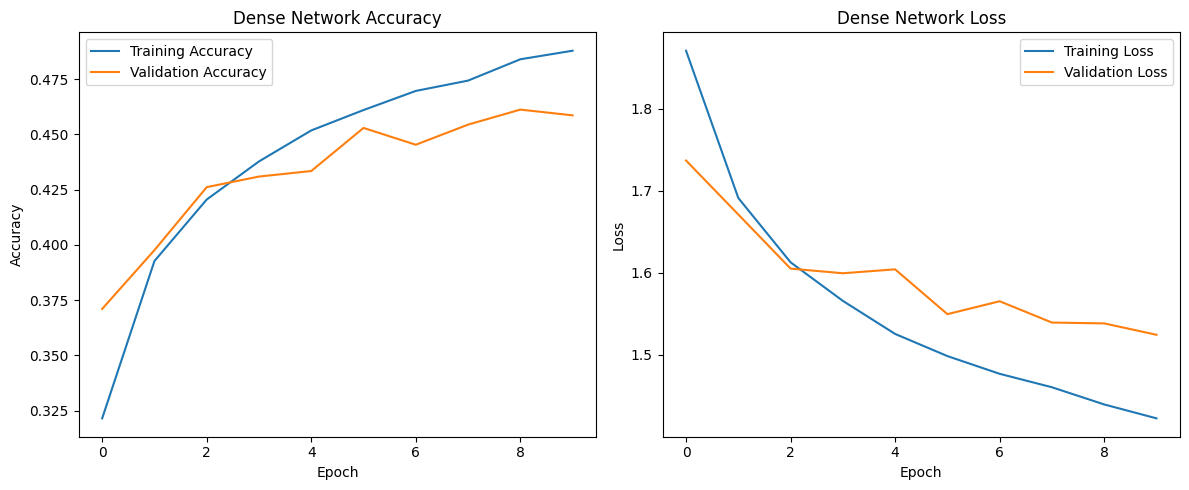

In [20]:


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(dense_history.history['accuracy'], label='Training Accuracy')

plt.plot(dense_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Dense Network Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1, 2, 2)

plt.plot(dense_history.history['loss'], label='Training Loss')

plt.plot(dense_history.history['val_loss'], label='Validation Loss')

plt.title("Dense Network Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

# 2(c) CNN Model

**Build CNN model**

In [21]:
cnn_model = keras.Sequential([

    layers.Input(shape=(32, 32, 3)),


    layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(
        64,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')

], name="CNN_Model")


cnn_model.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']

)

cnn_model.summary()

Model: "CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

# Verify CNN parameters

In [22]:
cnn_parameters = cnn_model.count_params()

print("CNN Parameters:", cnn_parameters)

print("Hand Calculated Parameters:", 356810)

CNN Parameters: 356810
Hand Calculated Parameters: 356810


Train CNN for 10 epochs

In [23]:
cnn_timer = EpochTimer()

cnn_history = cnn_model.fit(

    x_train,
    y_train,

    epochs=10,

    batch_size=32,

    validation_split=0.2,

    callbacks=[cnn_timer],

    verbose=1

)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.4713 - loss: 1.4635 - val_accuracy: 0.5994 - val_loss: 1.1364
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6392 - loss: 1.0247 - val_accuracy: 0.6678 - val_loss: 0.9348
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6995 - loss: 0.8555 - val_accuracy: 0.6910 - val_loss: 0.8954
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7443 - loss: 0.7358 - val_accuracy: 0.7087 - val_loss: 0.8591
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7724 - loss: 0.6451 - val_accuracy: 0.7116 - val_loss: 0.8755
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8012 - loss: 0.5683 - val_accuracy: 0.7065 - val_loss: 0.9438
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8245 - loss: 0.5028 - val_accuracy: 0.6987 - val_loss: 1.0334
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8448 - loss: 0.4430 

**Evaluate CNN**

In [24]:
cnn_train_loss, cnn_train_acc = cnn_model.evaluate(
    x_train, y_train, verbose=0
)

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(
    x_test, y_test, verbose=0
)

cnn_val_acc = cnn_history.history['val_accuracy'][-1]

print("CNN Results")

print("Training Accuracy:", cnn_train_acc)

print("Validation Accuracy:", cnn_val_acc)

print("Testing Accuracy:", cnn_test_acc)

print(
    "Average Time Per Epoch:",
    np.mean(cnn_timer.epoch_times),
    "seconds"
)

CNN Results
Training Accuracy: 0.8082600235939026
Validation Accuracy: 0.6862000226974487
Testing Accuracy: 0.6881999969482422
Average Time Per Epoch: 7.909288501739502 seconds


**Compare Dense Network and CNN**

In [25]:
comparison = pd.DataFrame({

    'Model': [
        'Dense Network',
        'CNN'
    ],

    'Parameters': [
        dense_parameters,
        cnn_parameters
    ],

    'Training Accuracy': [
        dense_train_acc,
        cnn_train_acc
    ],

    'Validation Accuracy': [
        dense_val_acc,
        cnn_val_acc
    ],

    'Test Accuracy': [
        dense_test_acc,
        cnn_test_acc
    ],

    'Time Per Epoch': [
        np.mean(dense_timer.epoch_times),
        np.mean(cnn_timer.epoch_times)
    ]

})

display(comparison)

,Model,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Time Per Epoch
0,Dense Network,855050,0.49188,0.4586,0.4720,4.640060
1,CNN,356810,0.80826,0.6862,0.6882,7.909289


In [26]:
comparison = pd.DataFrame({

    'Model': [
        'Dense Network',
        'CNN'
    ],

    'Parameters': [
        dense_parameters,
        cnn_parameters
    ],

    'Training Accuracy': [
        dense_train_acc,
        cnn_train_acc
    ],

    'Validation Accuracy': [
        dense_val_acc,
        cnn_val_acc
    ],

    'Test Accuracy': [
        dense_test_acc,
        cnn_test_acc
    ],

    'Time Per Epoch': [
        np.mean(dense_timer.epoch_times),
        np.mean(cnn_timer.epoch_times)
    ]

})

display(comparison)

,Model,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Time Per Epoch
0,Dense Network,855050,0.49188,0.4586,0.4720,4.640060
1,CNN,356810,0.80826,0.6862,0.6882,7.909289


# 2(d) Experiments — Change One Thing at a Time

**Create a CNN builder for experiments**

In [27]:
def build_experiment_cnn(
    dropout_rate=0.0,
    batch_norm=False,
    optimizer_name='adam'
):

    model = keras.Sequential([

        layers.Input(shape=(32, 32, 3)),

        layers.Conv2D(32, (3, 3),
                      activation='relu',
                      padding='same'),

        layers.MaxPooling2D((2, 2)),

        *([layers.BatchNormalization()] if batch_norm else []),

        *([layers.Dropout(dropout_rate)] if dropout_rate > 0 else []),

        layers.Conv2D(64, (3, 3),
                      activation='relu',
                      padding='same'),

        layers.MaxPooling2D((2, 2)),

        *([layers.BatchNormalization()] if batch_norm else []),

        *([layers.Dropout(dropout_rate)] if dropout_rate > 0 else []),

        layers.Conv2D(128, (3, 3),
                      activation='relu',
                      padding='same'),

        layers.MaxPooling2D((2, 2)),

        *([layers.BatchNormalization()] if batch_norm else []),

        *([layers.Dropout(dropout_rate)] if dropout_rate > 0 else []),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),

        layers.Dense(10, activation='softmax')

    ])


    if optimizer_name == 'adam':

        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    elif optimizer_name == 'sgd':

        optimizer = keras.optimizers.SGD(learning_rate=0.001)

    elif optimizer_name == 'sgd_momentum':

        optimizer = keras.optimizers.SGD(
            learning_rate=0.001,
            momentum=0.9
        )

    elif optimizer_name == 'rmsprop':

        optimizer = keras.optimizers.RMSprop(learning_rate=0.001)

    else:
        raise ValueError("Invalid optimizer")

    model.compile(

        optimizer=optimizer,

        loss='categorical_crossentropy',

        metrics=['accuracy']

    )

    return model

**Create experiment training function**
Builds the CNN.



Trains it for 10 epochs.



Calculates training accuracy.



Calculates validation accuracy.



Calculates test accuracy.



Records time per epoch.



Returns the trained model.

In [28]:
def run_experiment(
    experiment_name,
    batch_size=32,
    dropout_rate=0.0,
    batch_norm=False,
    optimizer_name='adam'
):

    print("\nStarting:", experiment_name)

    model = build_experiment_cnn(
        dropout_rate=dropout_rate,
        batch_norm=batch_norm,
        optimizer_name=optimizer_name
    )


    timer = EpochTimer()


    history = model.fit(

        x_train,
        y_train,

        epochs=10,

        batch_size=batch_size,

        validation_split=0.2,

        callbacks=[timer],

        verbose=1

    )


    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    result = {

        'Configuration': experiment_name,

        'Batch Size': batch_size,

        'Dropout': dropout_rate,

        'Batch Normalization': batch_norm,

        'Optimizer': optimizer_name,

        'Parameters': model.count_params(),

        'Training Accuracy': history.history['accuracy'][-1],

        'Validation Accuracy': history.history['val_accuracy'][-1],

        'Test Accuracy': test_accuracy,

        'Time Per Epoch': np.mean(timer.epoch_times)

    }

    print("Experiment completed:", experiment_name)

    return result, model, history

**Prepare result storage**

In [14]:
experiment_results = []


experiment_models = {}

experiment_histories = {}

**Record batch size 32 baseline**

In [29]:


baseline_result = {

    'Configuration': 'Batch Size 32',

    'Batch Size': 32,

    'Dropout': 0.0,

    'Batch Normalization': False,

    'Optimizer': 'adam',

    'Parameters': cnn_model.count_params(),

    'Training Accuracy': cnn_history.history['accuracy'][-1],

    'Validation Accuracy': cnn_history.history['val_accuracy'][-1],

    'Test Accuracy': cnn_test_acc,

    'Time Per Epoch': np.mean(cnn_timer.epoch_times)

}

experiment_results.append(baseline_result)

experiment_models['Batch Size 32'] = cnn_model

experiment_histories['Batch Size 32'] = cnn_history

print("Batch size 32 baseline recorded.")

Batch size 32 baseline recorded.


**Train batch sizes 16, 128 and 512**

In [30]:
batch_sizes = [16, 128, 512]

for batch in batch_sizes:

    result, model, history = run_experiment(

        experiment_name=f'Batch Size {batch}',

        batch_size=batch,

        dropout_rate=0.0,

        batch_norm=False,

        optimizer_name='adam'

    )

    experiment_results.append(result)

    experiment_models[f'Batch Size {batch}'] = model

    experiment_histories[f'Batch Size {batch}'] = history


Starting: Batch Size 16
Epoch 1/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.4861 - loss: 1.4134 - val_accuracy: 0.5866 - val_loss: 1.1651
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.6511 - loss: 0.9926 - val_accuracy: 0.6674 - val_loss: 0.9521
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7102 - loss: 0.8240 - val_accuracy: 0.6961 - val_loss: 0.8950
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.7541 - loss: 0.7029 - val_accuracy: 0.7033 - val_loss: 0.9272
Epoch 5/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.7894 - loss: 0.6032 - val_accuracy: 0.7016 - val_loss: 0.9681
Epoch 6/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8150 - loss: 0.5261 - val_accuracy: 0.7022 - val_loss: 1.0457
Epoch 7/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8378 - loss: 0.4626 - val_accuracy: 0.6897 - val_loss: 1.1501
Epoch 8/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - a

**Train Dropout experiments**

In [31]:
dropout_rates = [0.1, 0.25, 0.5]

for rate in dropout_rates:

    result, model, history = run_experiment(

        experiment_name=f'Dropout {rate}',

        batch_size=32,

        dropout_rate=rate,

        batch_norm=False,

        optimizer_name='adam'

    )

    experiment_results.append(result)

    experiment_models[f'Dropout {rate}'] = model

    experiment_histories[f'Dropout {rate}'] = history


Starting: Dropout 0.1
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - accuracy: 0.4475 - loss: 1.5202 - val_accuracy: 0.5676 - val_loss: 1.2137
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6043 - loss: 1.1129 - val_accuracy: 0.6558 - val_loss: 0.9765
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6669 - loss: 0.9424 - val_accuracy: 0.6877 - val_loss: 0.8940
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7075 - loss: 0.8324 - val_accuracy: 0.6941 - val_loss: 0.8814
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7363 - loss: 0.7517 - val_accuracy: 0.7147 - val_loss: 0.8324
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7571 - loss: 0.6941 - val_accuracy: 0.7187 - val_loss: 0.8236
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7746 - loss: 0.6367 - val_accuracy: 0.7157 - val_loss: 0.8477
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 

**Train Batch Normalization model**

In [32]:
result, model, history = run_experiment(

    experiment_name='BatchNorm + Dropout 0.25',

    batch_size=32,

    dropout_rate=0.25,

    batch_norm=True,

    optimizer_name='adam'

)

experiment_results.append(result)

experiment_models['BatchNorm + Dropout 0.25'] = model

experiment_histories['BatchNorm + Dropout 0.25'] = history


Starting: BatchNorm + Dropout 0.25
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.4972 - loss: 1.4249 - val_accuracy: 0.5772 - val_loss: 1.1786
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6273 - loss: 1.0449 - val_accuracy: 0.6544 - val_loss: 0.9983
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6808 - loss: 0.8964 - val_accuracy: 0.6686 - val_loss: 0.9583
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7184 - loss: 0.7949 - val_accuracy: 0.7053 - val_loss: 0.8547
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7474 - loss: 0.7102 - val_accuracy: 0.6810 - val_loss: 0.9637
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7662 - loss: 0.6572 - val_accuracy: 0.7206 - val_loss: 0.8636
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7868 - loss: 0.6056 - val_accuracy: 0.7136 - val_loss: 0.8837
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step

**Train optimizer experiments**

In [33]:
optimizers = [
    'sgd',
    'sgd_momentum',
    'rmsprop',
    'adam'
]

for opt in optimizers:

    if opt == 'adam':

        result = baseline_result

        experiment_results.append({
            **result,
            'Configuration': 'Optimizer Adam'
        })

        experiment_models['Optimizer Adam'] = cnn_model

        experiment_histories['Optimizer Adam'] = cnn_history

        continue

    result, model, history = run_experiment(

        experiment_name=f'Optimizer {opt}',

        batch_size=32,

        dropout_rate=0.0,

        batch_norm=False,

        optimizer_name=opt

    )

    experiment_results.append(result)

    experiment_models[f'Optimizer {opt}'] = model

    experiment_histories[f'Optimizer {opt}'] = history


Starting: Optimizer sgd
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.1330 - loss: 2.2983 - val_accuracy: 0.1443 - val_loss: 2.2899
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1648 - loss: 2.2820 - val_accuracy: 0.1678 - val_loss: 2.2708
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.1960 - loss: 2.2511 - val_accuracy: 0.2015 - val_loss: 2.2219
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.2421 - loss: 2.1624 - val_accuracy: 0.2593 - val_loss: 2.0873
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.2820 - loss: 2.0180 - val_accuracy: 0.2972 - val_loss: 1.9800
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3070 - loss: 1.9456 - val_accuracy: 0.3212 - val_loss: 1.9302
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3307 - loss: 1.8968 - val_accuracy: 0.3401 - val_loss: 1.8816
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy:

**Create the complete comparison table**

In [34]:

results_df = pd.DataFrame(experiment_results)
display(results_df.round(4))


results_df.to_csv(
    'task2_experimental_results.csv',
    index=False
)

print("Experimental results saved successfully.")

,Configuration,Batch Size,Dropout,Batch Normalization,Optimizer,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Time Per Epoch
0,Batch Size 32,32,0.00,False,adam,356810,0.8784,0.6862,0.6882,7.9093
1,Batch Size 16,16,0.00,False,adam,356810,0.8845,0.6990,0.6912,14.7944
2,Batch Size 128,128,0.00,False,adam,356810,0.8288,0.7108,0.7115,5.6855
3,Batch Size 512,512,0.00,False,adam,356810,0.7253,0.6815,0.6809,3.8482
4,Dropout 0.1,32,0.10,False,adam,356810,0.8169,0.7330,0.7300,7.5593
5,Dropout 0.25,32,0.25,False,adam,356810,0.7435,0.7449,0.7401,6.3915
6,Dropout 0.5,32,0.50,False,adam,356810,0.6366,0.6713,0.6647,6.4007
7,BatchNorm + Dropout 0.25,32,0.25,True,adam,357706,0.8257,0.7424,0.7347,7.2436
8,Optimizer sgd,32,0.00,False,sgd,356810,0.3877,0.3988,0.4048,5.7834
9,Optimizer sgd_momentum,32,0.00,False,sgd_momentum,356810,0.6864,0.6479,0.6492,6.3201


Experimental results saved successfully.


**Compare Dense Network with all CNN configurations**

In [35]:


dense_row = {

    'Configuration': 'Dense Baseline',

    'Batch Size': 32,

    'Dropout': 0.0,

    'Batch Normalization': False,

    'Optimizer': 'adam',

    'Parameters': dense_parameters,

    'Training Accuracy': dense_train_acc,

    'Validation Accuracy': dense_val_acc,

    'Test Accuracy': dense_test_acc,

    'Time Per Epoch': np.mean(dense_timer.epoch_times)

}


complete_results = pd.concat(

    [pd.DataFrame([dense_row]), results_df],

    ignore_index=True

)

display(complete_results.round(4))


complete_results.to_csv(
    'task2_complete_comparison.csv',
    index=False
)

,Configuration,Batch Size,Dropout,Batch Normalization,Optimizer,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Time Per Epoch
0,Dense Baseline,32,0.00,False,adam,855050,0.4919,0.4586,0.4720,4.6401
1,Batch Size 32,32,0.00,False,adam,356810,0.8784,0.6862,0.6882,7.9093
2,Batch Size 16,16,0.00,False,adam,356810,0.8845,0.6990,0.6912,14.7944
3,Batch Size 128,128,0.00,False,adam,356810,0.8288,0.7108,0.7115,5.6855
4,Batch Size 512,512,0.00,False,adam,356810,0.7253,0.6815,0.6809,3.8482
5,Dropout 0.1,32,0.10,False,adam,356810,0.8169,0.7330,0.7300,7.5593
6,Dropout 0.25,32,0.25,False,adam,356810,0.7435,0.7449,0.7401,6.3915
7,Dropout 0.5,32,0.50,False,adam,356810,0.6366,0.6713,0.6647,6.4007
8,BatchNorm + Dropout 0.25,32,0.25,True,adam,357706,0.8257,0.7424,0.7347,7.2436
9,Optimizer sgd,32,0.00,False,sgd,356810,0.3877,0.3988,0.4048,5.7834


# 2(e) Analysis — Confusion Matrix and Predictions

In [36]:

best_index = results_df['Validation Accuracy'].idxmax()

best_configuration = results_df.loc[best_index, 'Configuration']

best_model = experiment_models[best_configuration]

print("Best CNN Configuration:", best_configuration)

print("Best Validation Accuracy:",
      results_df.loc[best_index, 'Validation Accuracy'])

print("Best Model Parameters:", best_model.count_params())

Best CNN Configuration: Dropout 0.25
Best Validation Accuracy: 0.7448999881744385
Best Model Parameters: 356810


**Generate predictions on test data**

In [37]:

predictions = best_model.predict(x_test, verbose=1)


y_pred = np.argmax(predictions, axis=1)


y_true = np.argmax(y_test, axis=1)

print("Predictions generated successfully.")

print("Predicted labels shape:", y_pred.shape)

print("True labels shape:", y_true.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predictions generated successfully.
Predicted labels shape: (10000,)
True labels shape: (10000,)


**Plot confusion matrix**

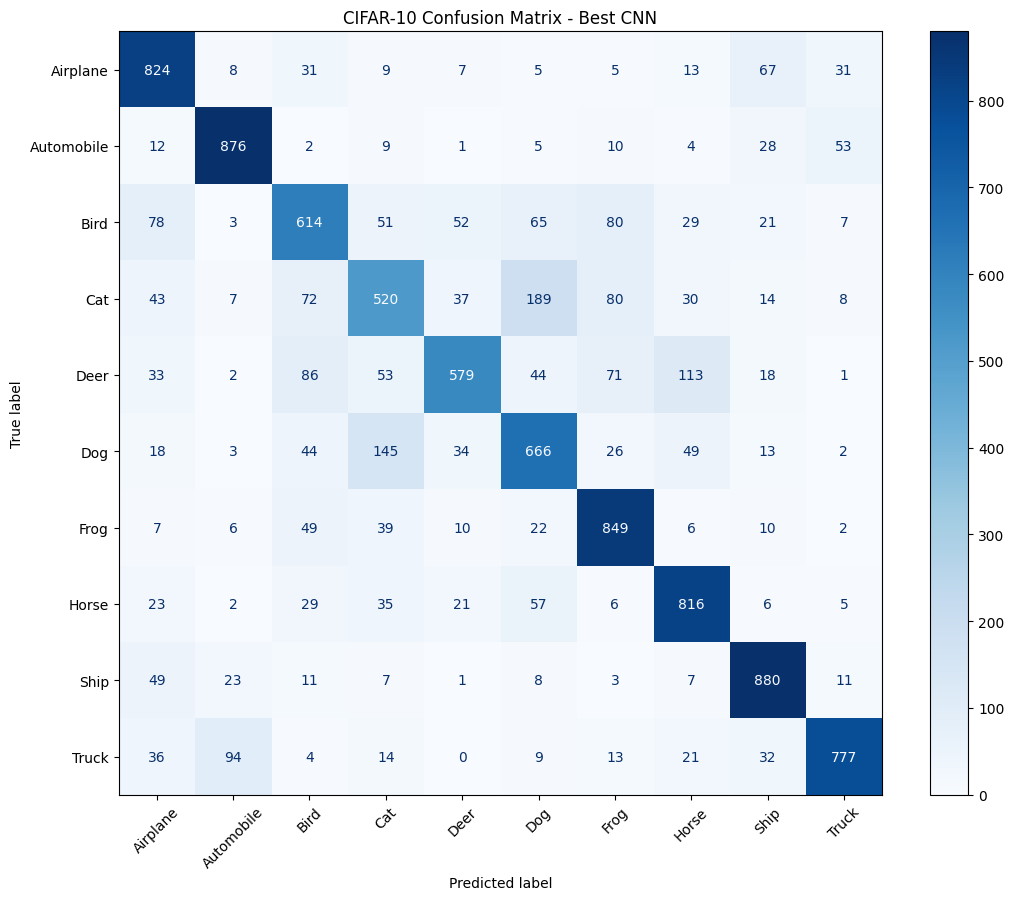

In [38]:

cm = confusion_matrix(y_true, y_pred)


fig, ax = plt.subplots(figsize=(11, 9))

display_cm = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=class_names

)

display_cm.plot(

    cmap='Blues',

    xticks_rotation=45,

    ax=ax,

    colorbar=True

)

plt.title("CIFAR-10 Confusion Matrix - Best CNN")

plt.tight_layout()

plt.show()

Find the most confused classes

In [40]:
cm_errors = cm.copy()


np.fill_diagonal(cm_errors, 0)


confused_pairs = []

for i in range(10):

    for j in range(10):

        if cm_errors[i, j] > 0:

            confused_pairs.append({

                'Actual Class': class_names[i],

                'Predicted Class': class_names[j],

                'Number of Errors': cm_errors[i, j]

            })


confused_df = pd.DataFrame(confused_pairs)

confused_df = confused_df.sort_values(

    by='Number of Errors',

    ascending=False

)

display(confused_df.head(10))


confused_df.to_csv(

    'task2_most_confused_classes.csv',

    index=False

)

,Actual Class,Predicted Class,Number of Errors
31,Cat,Dog,189
48,Dog,Cat,145
42,Deer,Horse,113
82,Truck,Automobile,94
38,Deer,Bird,86
32,Cat,Frog,80
23,Bird,Frog,80
18,Bird,Airplane,78
29,Cat,Bird,72
41,Deer,Frog,71


**Display 20 test images with true and predicted labels**

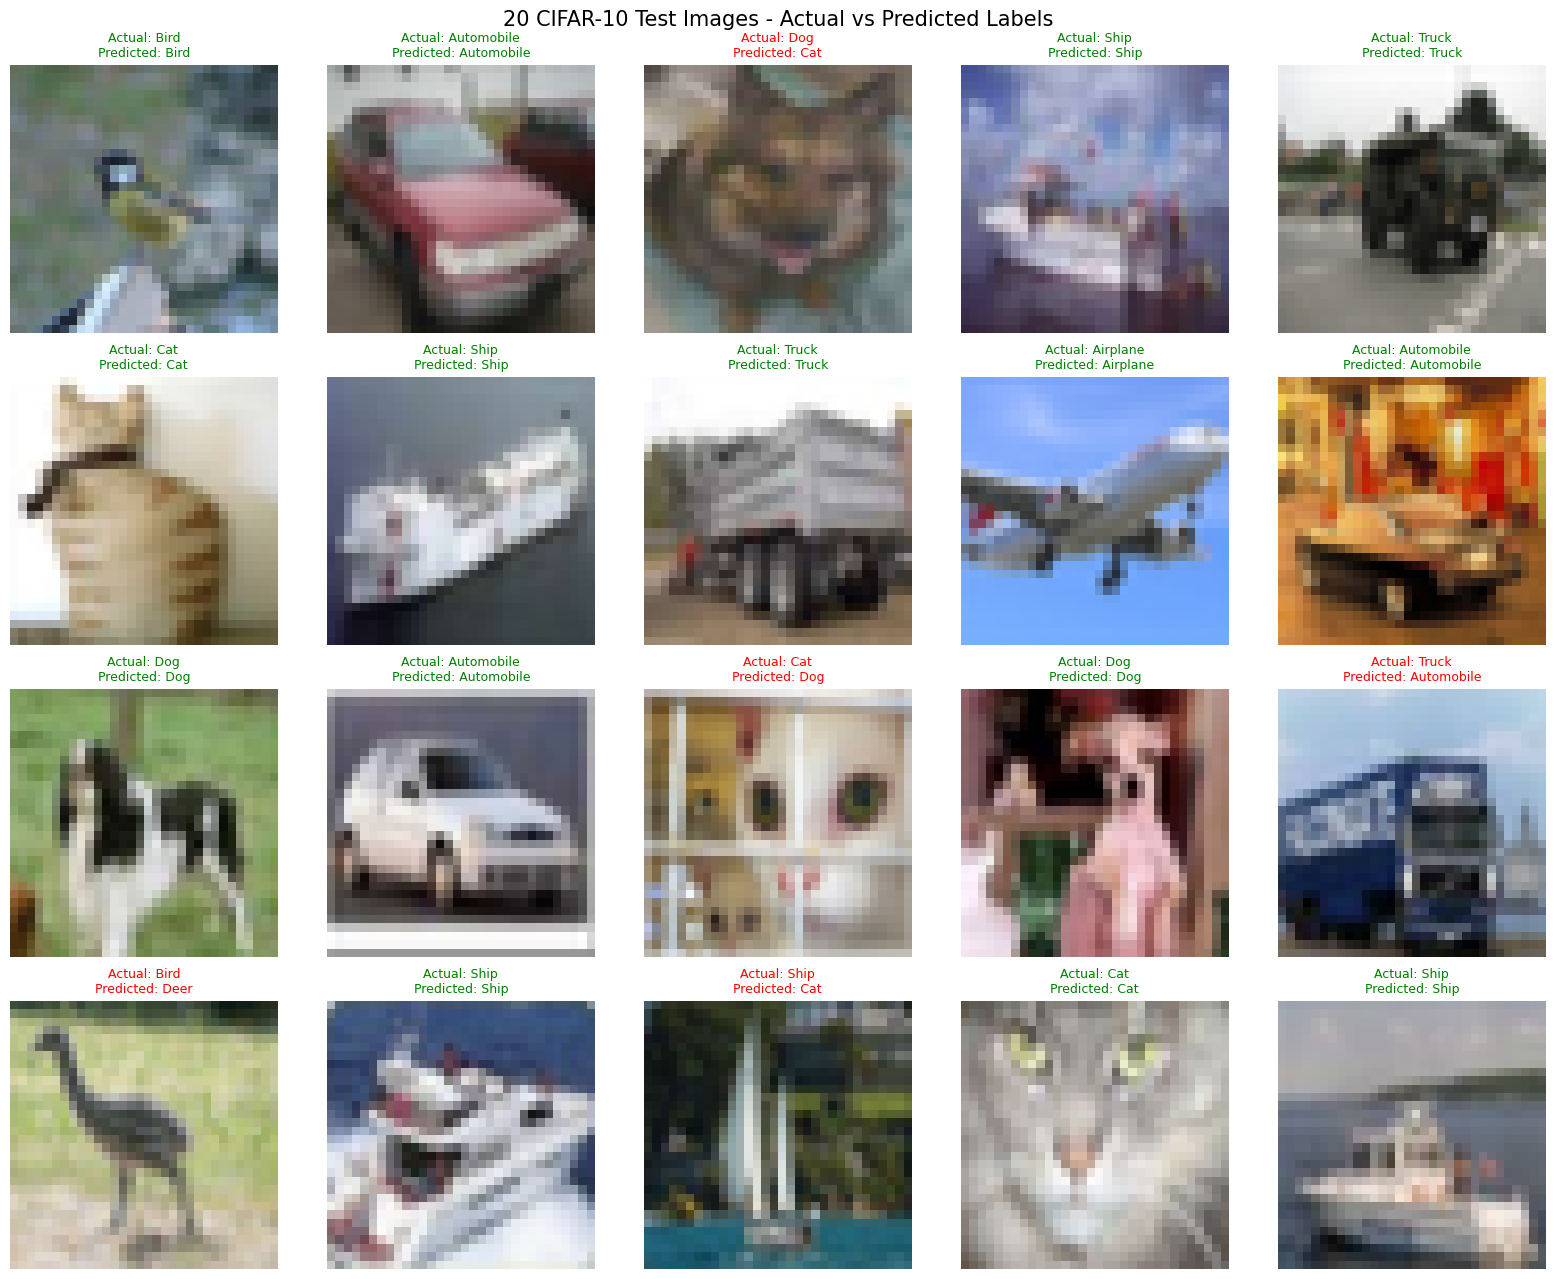

In [41]:

np.random.seed(42)

sample_indices = np.random.choice(

    len(x_test),

    size=20,

    replace=False

)

fig, axes = plt.subplots(4, 5, figsize=(16, 13))

for ax, idx in zip(axes.flat, sample_indices):


    ax.imshow(x_test[idx])



    actual_label = class_names[y_true[idx]]

    predicted_label = class_names[y_pred[idx]]

    if y_true[idx] == y_pred[idx]:

        color = 'green'

    else:

        color = 'red'

    ax.set_title(

        f"Actual: {actual_label}\nPredicted: {predicted_label}",

        color=color,

        fontsize=9

    )

    ax.axis('off')


plt.suptitle(

    "20 CIFAR-10 Test Images - Actual vs Predicted Labels",

    fontsize=15

)

plt.tight_layout()

plt.show()

**Save final Task 2 results**

In [42]:

best_model.save('task2_best_cnn.keras')



np.savetxt(

    'task2_confusion_matrix.csv',

    cm,

    delimiter=',',

    fmt='%d'

)


complete_results.to_csv(

    'task2_final_results.csv',

    index=False

)

print("Task 2 files saved successfully.")

Task 2 files saved successfully.
